<a href="https://colab.research.google.com/github/GrimiDev12/Programaci-n-para-IA-gpo-001/blob/main/AF3-EntrenarArbol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Fundamental 3

# Ejercicio 1 Carga del procesamiento de datos

Descripcion: En este primer bloque se importan las librerías esenciales para el flujo de trabajo: pandas y numpy para el manejo de estructuras de datos y operaciones numéricas, matplotlib.pyplot para la generación de gráficos, y los módulos de scikit-learn para particionar los datos, construir el árbol de decisión y evaluar su rendimiento. Posteriormente, se lee el conjunto de datos público Pima Indians Diabetes directamente desde su URL en formato CSV. Dado que el archivo original carece de encabezados, se define manualmente la lista con los nombres de las 8 variables clínicas predictoras y la variable objetivo (Outcome), verificando la correcta carga mediante la impresión de las primeras 5 filas con el método head().

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# URL pública del dataset de Diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


# Ejercicio 2 Analisis de los datos

Descripcion: Se realiza una exploración inicial del DataFrame utilizando info() e isnull().sum() para verificar los tipos de datos y comprobar que no existen valores nulos explícitos de origen. A continuación, con el método describe() se obtiene el resumen estadístico completo (media, desviación estándar, valores mínimos, máximos y cuartiles), lo que permite identificar anomalías críticas: variables como Glucose, BloodPressure, SkinThickness, Insulin y BMI presentan valores mínimos de 0, los cuales son biológicamente imposibles y representan datos faltantes encubiertos. Finalmente, se emplea matplotlib para generar un diagrama de dispersión (scatter plot) que relaciona los niveles de Glucosa (eje X) con el Índice de Masa Corporal o BMI (eje Y), separando mediante filtros y colores a los pacientes sanos (Outcome igual a 0) de aquellos con diabetes (Outcome igual a 1).

Info del DataFrame
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

 Conteo de Nulos
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunctio

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


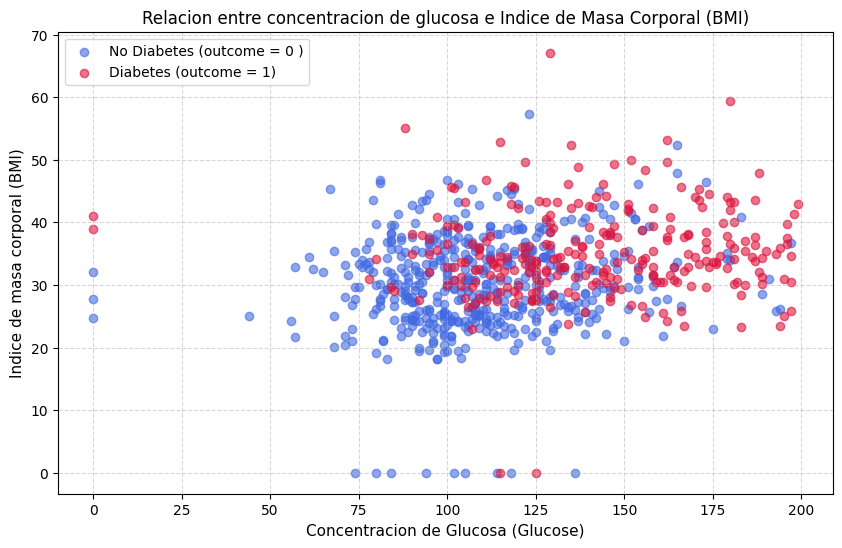

In [8]:
# Se usa para sacar informacion del dataframe
print("Info del DataFrame")
df.info()

print("\n Conteo de Nulos")
print(df.isnull().sum())

print("\n Resumen Estadistico")
display(df.describe())

# Creacion de la grafica
plt.figure(figsize=(10, 6))

NAdiabetes = df[df['Outcome'] == 0]
diabetes = df[df['Outcome'] == 1]


plt.scatter(NAdiabetes['Glucose'], NAdiabetes['BMI'], color='royalblue', alpha=0.6, label='No Diabetes (outcome = 0 )')
plt.scatter(diabetes['Glucose'], diabetes['BMI'], color='crimson', alpha=0.6, label='Diabetes (outcome = 1)')
plt.title('Relacion entre concentracion de glucosa e Indice de Masa Corporal (BMI)')
plt.xlabel('Concentracion de Glucosa (Glucose)', fontsize=11)
plt.ylabel('Indice de masa corporal (BMI)', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Ejercicio 3 Limpieza y Preprocesamiento de datos

Descripcion: Para corregir las anomalías detectadas en el análisis exploratorio, se trabaja sobre una copia del DataFrame y se reemplazan los valores de 0 por valores nulos estándar (NaN) en las cinco columnas clínicas donde el cero es inválido (Glucose, BloodPressure, SkinThickness, Insulin y BMI). Antes de rellenar los vacíos, se utilizan las funciones de numpy (nanpercentile) para calcular los percentiles 25 (Q1) y 75 (Q3) de la columna Insulin sobre las mediciones reales, evitando que la alta proporción de datos faltantes distorsione la varianza. Después, se imputan todos los valores nulos utilizando la mediana de cada columna para no perder registros ni sesgar la distribución ante valores extremos. Por último, se calcula el Rango Intercuartílico (IQR = Q3 - Q1) y se filtra el conjunto de datos conservando únicamente a los pacientes cuya insulina se encuentra dentro de los límites aceptables (entre Q1 - 1.5 por el IQR y Q3 + 1.5 por el IQR).

In [9]:
df_limpio = df.copy()


# Se detectaran las columnas con valores nulos y se reemplazara el 0 por NaN
columnas_con_ceros = ['Glucose','BloodPressure','SkinThickness', 'Insulin', 'BMI']
df_limpio[columnas_con_ceros] = df_limpio[columnas_con_ceros].replace(0, np.nan)
print("Cantidad de valores nulos encontrados por columna")
print(df_limpio.isnull().sum())


# Se calculara el Q1, Q3 y el IQR de Insulin ignorando los valores NaN
Q1 = np.nanpercentile(df_limpio['Insulin'], 25)
Q3 = np.nanpercentile(df_limpio['Insulin'], 75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
print(f"Estadisticas reales de Insulina - Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Limite inferior: {limite_inferior:.2f} | Limite superior:{limite_superior:.2f}")


#Se calculara la mediana
medianas = df_limpio[columnas_con_ceros].median()
df_limpio[columnas_con_ceros]=df_limpio[columnas_con_ceros].fillna(medianas)
print("Medianas utilizadas para la imputacion")
print(medianas)

# Se filtraran los valores raros en Insulin
filas_antes = df_limpio.shape[0]
condicion_iqr = (df_limpio['Insulin'] >= limite_inferior) & (df_limpio['Insulin'] <= limite_superior)
df_limpio = df_limpio[condicion_iqr]
filas_despues = df_limpio.shape[0]
print(f"Filas antes del filtro IQR: {filas_antes} | Filas despues del filtro IQR: {filas_despues}")



Cantidad de valores nulos encontrados por columna
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Estadisticas reales de Insulina - Q1: 76.25 | Q3: 190.00 | IQR: 113.75
Limite inferior: -94.38 | Limite superior:360.62
Medianas utilizadas para la imputacion
Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64
Filas antes del filtro IQR: 768 | Filas despues del filtro IQR: 744


# Ejercicio 4 Optimizacion del arbol

Descripcion: Para corregir las anomalías detectadas en el análisis exploratorio, se trabaja sobre una copia del DataFrame y se reemplazan los valores de 0 por valores nulos estándar (NaN) en las cinco columnas clínicas donde el cero es inválido (Glucose, BloodPressure, SkinThickness, Insulin y BMI). Antes de rellenar los vacíos, se utilizan las funciones de numpy (nanpercentile) para calcular los percentiles 25 (Q1) y 75 (Q3) de la columna Insulin sobre las mediciones reales, evitando que la alta proporción de datos faltantes distorsione la varianza. Después, se imputan todos los valores nulos utilizando la mediana de cada columna para no perder registros ni sesgar la distribución ante valores extremos. Por último, se calcula el Rango Intercuartílico (IQR = Q3 - Q1) y se filtra el conjunto de datos conservando únicamente a los pacientes cuya insulina se encuentra dentro de los límites aceptables (entre Q1 - 1.5 por el IQR y Q3 + 1.5 por el IQR).

--Comparativa de arboles--
Arbol Base -------->   Train Accuracy: 100.00% | Test Accuracy: 70.97%  | Profundidad: 16
Arbol Optimizado ------>    Train Accuracy: 83.33% | Test Accuracy: 72.04% | Profundidad: 5

Mejores Hiperparametros escogidos: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 20}

---Reporte de clasificacion del arbol optimizado---
                  precision    recall  f1-score   support

Sin diabetes (0)       0.78      0.80      0.79       122
Con Diabetes (1)       0.60      0.58      0.59        64

        accuracy                           0.72       186
       macro avg       0.69      0.69      0.69       186
    weighted avg       0.72      0.72      0.72       186



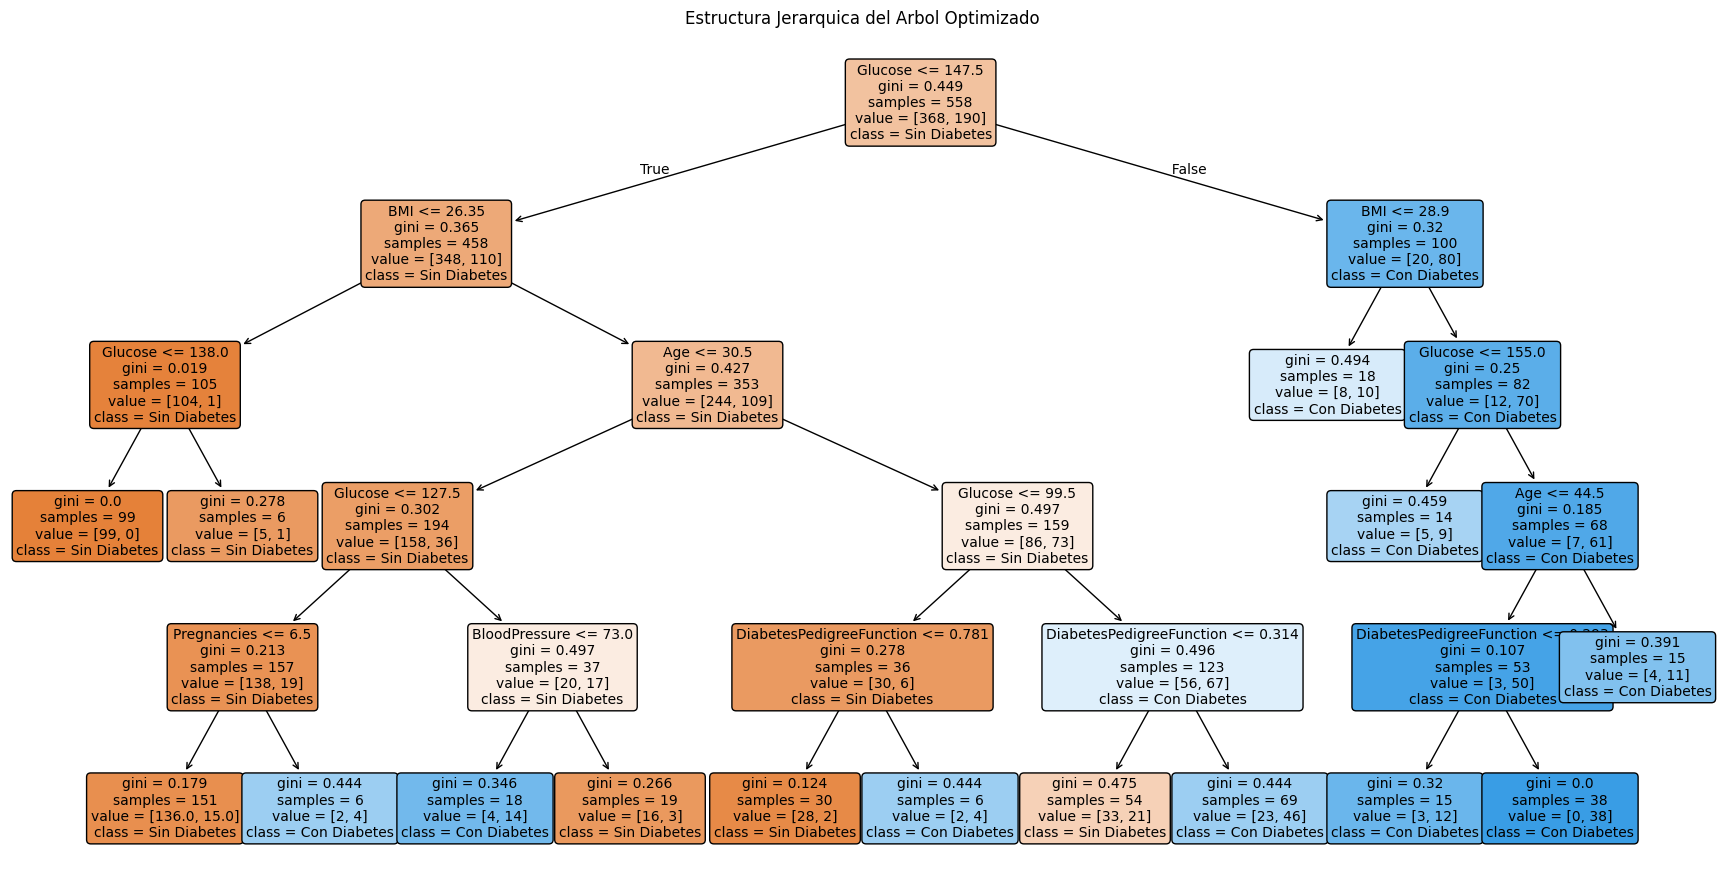

In [10]:
from sklearn.model_selection import GridSearchCV

# Se separara las matrices de caracteristicas (x) y el vector objetivo (y)
x = df_limpio.drop('Outcome', axis=1)
y = df_limpio['Outcome']

# Particion Estrateficada del conjunto de datos
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

# Entrenar al arbol sin restricciones como referencia
arbol_base = DecisionTreeClassifier(random_state=42)
arbol_base.fit(x_train, y_train)
y_pred_base = arbol_base.predict(x_test)

acc_train_base = accuracy_score(y_train, arbol_base.predict(x_train))
acc_test_base = accuracy_score(y_test, y_pred_base)


# Establecer los hiperparametros para podar y optimizar el arbol
param_grid = {
    'criterion' : ['gini','entropy'],
    'max_depth': [3, 4, 5, 6],
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf' : [5, 10, 15],
}

#Configurar la busqueda con el GridSearchCV
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(x_train, y_train)


# Extraer el mejor arbol y evaluar su desempeño
mejor_arbol = grid_search.best_estimator_
y_pred_opt = mejor_arbol.predict(x_test)

acc_train_opt = accuracy_score(y_train, mejor_arbol.predict(x_train))
acc_test_opt = accuracy_score(y_test, y_pred_opt)

print("--Comparativa de arboles--")
print(f"Arbol Base -------->   Train Accuracy: {acc_train_base*100:.2f}% | Test Accuracy: {acc_test_base*100:.2f}%  | Profundidad: {arbol_base.get_depth()}")
print(f"Arbol Optimizado ------>    Train Accuracy: {acc_train_opt*100:.2f}% | Test Accuracy: {acc_test_opt*100:.2f}% | Profundidad: {mejor_arbol.get_depth()}")
print(f"\nMejores Hiperparametros escogidos: {grid_search.best_params_}\n")
print("---Reporte de clasificacion del arbol optimizado---")
print(classification_report(y_test, y_pred_opt, target_names=['Sin diabetes (0)', 'Con Diabetes (1)']))
# Visualizacion de la estructura jerarquica del arbol
plt.figure(figsize=(22, 11))
plot_tree(
    mejor_arbol,
    feature_names=list(x.columns),
    class_names=['Sin Diabetes', 'Con Diabetes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura Jerarquica del Arbol Optimizado")
plt.show()